# Notebook 02 — Regresión reproducible sobre Airfoil

**Problema 6.** Predecir el nivel de ruido `sonido` (en dB) de un perfil alar a partir de `frecuencia`, `angulo`, `cuerda`, `velocidad` y `espesor`.

Pasos del notebook:

1. Revisar los datos crudos (auditoría).
2. Separar 80 % para desarrollo y 20 % para prueba.
3. Explorar los datos (EDA) **solo** con el conjunto de desarrollo.
4. Elegir representación y regularización con validación cruzada de 5 pliegues.
5. Evaluar una sola vez en prueba.

OLS, Ridge y Lasso son las implementaciones propias de `modelos.py`.

In [1]:
import json
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
# De scikit-learn solo usamos métricas, particiones y el escalador.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, KFold
from sklearn.preprocessing import StandardScaler

# Modelos propios.
from modelos import SEMILLA, LassoProximal, RegresionOLS, RegresionRidge

# Carpetas de datos y resultados.
DATA = Path("data")
RESULTADOS = Path("resultados")
PARAMETROS = RESULTADOS / "parametros"
PARAMETROS.mkdir(parents=True, exist_ok=True)

# Formato de tablas y gráficas.
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

## 6a. Datos crudos, auditoría y partición

### Carga

El archivo se descarga del UCI Machine Learning Repository (la misma fuente del notebook de regresión de clase), solo si todavía no está en `data/`. El archivo crudo nunca se modifica.

Cada fila recibe un `id` estable: su número de línea en el archivo (1 a 1503).

In [2]:
# Reutilizado de clase: descarga del ZIP de UCI y lectura con los nombres de columnas.
# Mejoras: id estable por número de línea.
RUTA = DATA / "airfoil_self_noise.dat"
URL = "https://archive.ics.uci.edu/static/public/291/airfoil+self+noise.zip"

if not RUTA.exists():
    DATA.mkdir(exist_ok=True)
    with urlopen(URL, timeout=60) as respuesta:
        contenido_zip = respuesta.read()
    # Del ZIP se extrae solo el archivo .dat.
    with ZipFile(BytesIO(contenido_zip)) as z:
        nombre_en_zip = next(n for n in z.namelist() if Path(n).name == RUTA.name)
        RUTA.write_bytes(z.read(nombre_en_zip))

# El archivo no tiene encabezado: le ponemos nombres a las columnas.
VARIABLES = ["frecuencia", "angulo", "cuerda", "velocidad", "espesor"]
OBJETIVO = "sonido"
crudo = pd.read_csv(RUTA, sep=r"\s+", header=None, names=VARIABLES + [OBJETIVO])
crudo.insert(0, "id", np.arange(1, len(crudo) + 1))      # id = número de línea en el archivo

print(f"{RUTA}: {crudo.shape[0]} filas x {crudo.shape[1] - 1} columnas")
crudo.head()

data\airfoil_self_noise.dat: 1503 filas x 6 columnas


,id,frecuencia,angulo,cuerda,velocidad,espesor,sonido
0,1,800,0.0,0.3048,71.3,0.0027,126.201
1,2,1000,0.0,0.3048,71.3,0.0027,125.201
2,3,1250,0.0,0.3048,71.3,0.0027,125.951
3,4,1600,0.0,0.3048,71.3,0.0027,127.591
4,5,2000,0.0,0.3048,71.3,0.0027,127.461


### Auditoría de formato, identidad y dominios

Se revisan tipos, faltantes, duplicados y rangos. Las unidades vienen de la documentación de UCI. Las reglas de dominio son físicas y fijas: no dependen de estadísticas de los datos, así que aplicarlas antes de partir no produce fuga.

| Variable | Qué mide | Unidad | Regla de dominio |
|---|---|---|---|
| `frecuencia` | Frecuencia del sonido | Hz | $> 0$ |
| `angulo` | Ángulo de ataque del perfil | grados | entre 0 y 90 |
| `cuerda` | Largo del perfil (cuerda) | m | $> 0$ |
| `velocidad` | Velocidad del aire | m/s | $> 0$ |
| `espesor` | Espesor de la capa límite en el lado de succión | m | $> 0$ |
| `sonido` | Nivel de presión sonora | dB | número finito |

In [3]:
# Cada regla devuelve True en las filas que la cumplen.
reglas = {
    "frecuencia": crudo["frecuencia"] > 0,
    "angulo":     crudo["angulo"].between(0, 90, inclusive="left"),
    "cuerda":     crudo["cuerda"] > 0,
    "velocidad":  crudo["velocidad"] > 0,
    "espesor":    crudo["espesor"] > 0,
    "sonido":     np.isfinite(crudo["sonido"]),
}
unidades = {"frecuencia": "Hz", "angulo": "grados", "cuerda": "m", "velocidad": "m/s",
            "espesor": "m", "sonido": "dB"}
fuera_de_dominio = {variable: int((~cumple).sum()) for variable, cumple in reglas.items()}

datos = crudo[VARIABLES + [OBJETIVO]]
auditoria = pd.DataFrame({
    "tipo": datos.dtypes.astype(str),
    "unidad": pd.Series(unidades),
    "faltantes": datos.isna().sum(),
    "valores únicos": datos.nunique(),
    "mínimo": datos.min(),
    "máximo": datos.max(),
    "fuera de dominio": pd.Series(fuera_de_dominio),
})
auditoria.to_csv(RESULTADOS / "p6_auditoria.csv")

# Duplicados exactos: filas idénticas en las 5 variables y en el sonido.
n_dup_filas = int(crudo.duplicated(subset=VARIABLES + [OBJETIVO]).sum())
print("Filas duplicadas exactas:", n_dup_filas)
print("Ids únicos:", crudo["id"].is_unique)
auditoria

Filas duplicadas exactas: 0
Ids únicos: True


,tipo,unidad,faltantes,valores únicos,mínimo,máximo,fuera de dominio
frecuencia,int64,Hz,0,21,200.0000,20000.0000,0
angulo,float64,grados,0,27,0.0000,22.2000,0
cuerda,float64,m,0,6,0.0254,0.3048,0
velocidad,float64,m/s,0,4,31.7000,71.3000,0
espesor,float64,m,0,105,0.0004,0.0584,0
sonido,float64,dB,0,1456,103.3800,140.9870,0


**Resultado de la auditoría.**

- Todas las columnas son numéricas, no tienen faltantes y están dentro de su dominio físico.
- No hay filas duplicadas.
- No hace falta ninguna regla de limpieza: se conservan las 1503 filas.
- Varias variables toman pocos valores distintos, porque el experimento usa niveles fijos: 4 velocidades, 6 cuerdas, 21 frecuencias y 27 ángulos.

### Partición 80/20

- Se separa el 20 % para prueba con `GroupShuffleSplit` y semilla 2026. Cada grupo reúne las filas idénticas, de modo que un duplicado exacto nunca podría quedar una vez en desarrollo y otra en prueba. Aquí no hay duplicados, así que cada grupo es una sola fila.
- En el mismo paso se fijan los 5 pliegues de validación cruzada dentro de desarrollo (`KFold` con mezcla y semilla 2026). Todos los modelos usarán exactamente esos pliegues.
- El manifiesto `p6_particiones.csv` guarda, para cada `id`, si está en desarrollo o en prueba y en qué pliegue.

In [4]:
# Filas idénticas reciben el mismo número de grupo, así nunca quedan separadas.
grupos = crudo.groupby(VARIABLES + [OBJETIVO]).ngroup()
particion = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
idx_des, idx_pru = next(particion.split(crudo, groups=grupos))

desarrollo = crudo.iloc[idx_des].reset_index(drop=True)
prueba = crudo.iloc[idx_pru].reset_index(drop=True)
assert set(grupos.iloc[idx_des]).isdisjoint(grupos.iloc[idx_pru])     # ningún grupo en ambos lados

# Pliegues de validación cruzada dentro de desarrollo, los mismos para todos los candidatos.
pliegues = list(KFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(desarrollo))

# Manifiesto: conjunto de cada id y, si está en desarrollo, su pliegue de validación.
manifiesto = pd.concat([desarrollo[["id"]].assign(conjunto="desarrollo"),
                        prueba[["id"]].assign(conjunto="prueba")]).set_index("id")
manifiesto["pliegue_validacion"] = pd.NA
for k, (_, idx_val) in enumerate(pliegues, start=1):
    ids_del_pliegue = desarrollo["id"].iloc[idx_val]
    manifiesto.loc[ids_del_pliegue, "pliegue_validacion"] = k
manifiesto.sort_index().to_csv(RESULTADOS / "p6_particiones.csv")

print(f"Desarrollo: {len(desarrollo)} filas | Prueba: {len(prueba)} filas")
print("Filas por pliegue de validación:", [len(v) for _, v in pliegues])

Desarrollo: 1202 filas | Prueba: 301 filas
Filas por pliegue de validación: [241, 241, 240, 240, 240]


### EDA sobre el conjunto de desarrollo

Desde aquí todo el análisis exploratorio usa solo las 1202 filas de desarrollo. Las hipótesis se escribieron antes de mirar las gráficas:

- **H1 (una variable a la vez).** `frecuencia` y `espesor` tienen una cola derecha larga, porque varían en más de un orden de magnitud. En acústica la frecuencia se suele analizar en escala logarítmica.
- **H2 (asociación).** El sonido no sube ni baja siempre con la frecuencia. Según el modelo físico de Brooks, Pope y Marcolini, del que vienen estos ensayos, el ruido se ordena mejor con el número de Strouhal $St = f\,\delta/U$ (frecuencia × espesor / velocidad) que con la frecuencia sola.
- **H3 (por grupos).** A mayor velocidad del aire, mayor nivel de ruido.

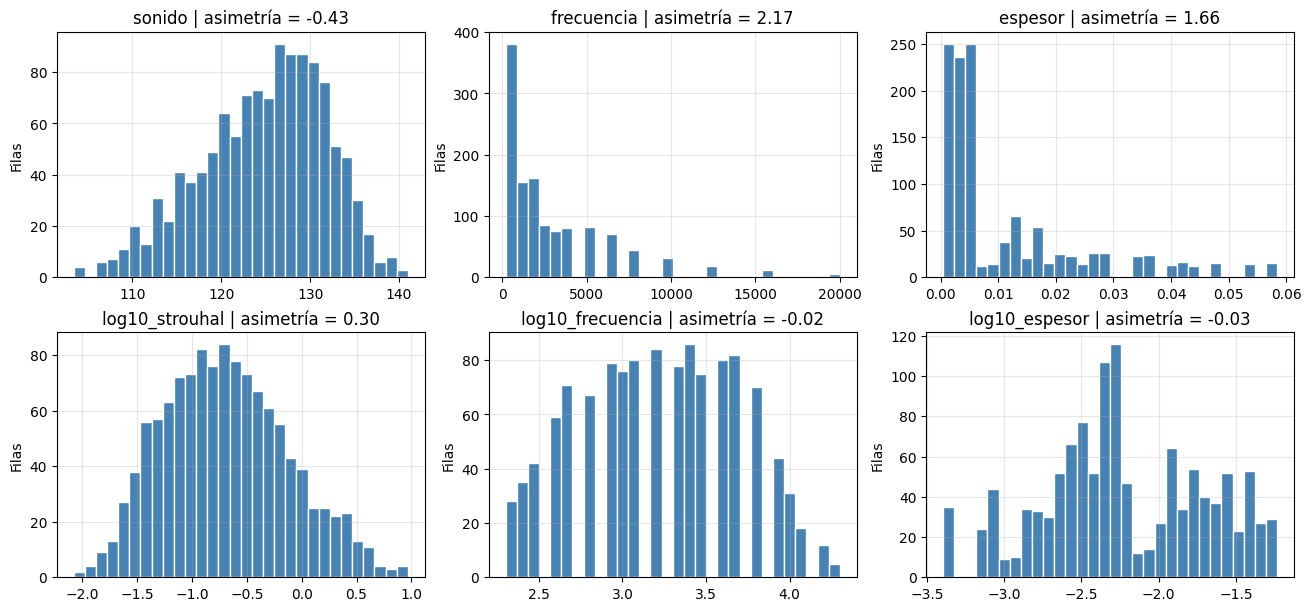

,count,mean,std,min,25%,50%,75%,max
sonido,1202.0,124.7669,7.0195,103.3800,120.1028,125.7160,130.0498,140.9870
frecuencia,1202.0,2878.3195,3170.4437,200.0000,630.0000,1600.0000,4000.0000,20000.0000
angulo,1202.0,6.8977,5.9299,0.0000,2.0000,5.4000,11.2000,22.2000
cuerda,1202.0,0.1374,0.0929,0.0254,0.0508,0.1016,0.2286,0.3048
velocidad,1202.0,51.2969,15.6537,31.7000,39.6000,55.5000,71.3000,71.3000
espesor,1202.0,0.0116,0.0135,0.0004,0.0027,0.0050,0.0161,0.0584


In [5]:
# H1: distribuciones de cada variable, en escala original y en escala logarítmica.
eda = desarrollo.copy()
eda["log10_frecuencia"] = np.log10(eda["frecuencia"])
eda["log10_espesor"] = np.log10(eda["espesor"])
eda["log10_strouhal"] = np.log10(eda["frecuencia"] * eda["espesor"] / eda["velocidad"])

columnas_hist = ["sonido", "frecuencia", "espesor", "log10_strouhal", "log10_frecuencia", "log10_espesor"]
fig, ax = plt.subplots(2, 3, figsize=(13, 6), constrained_layout=True)
for a, col in zip(ax.ravel(), columnas_hist):
    a.hist(eda[col], bins=30, color="steelblue", edgecolor="white")
    a.set(title=f"{col} | asimetría = {eda[col].skew():.2f}", ylabel="Filas")
plt.show()

eda[["sonido"] + VARIABLES].describe().T

**H1 se confirma.** `frecuencia` (asimetría 2.17) y `espesor` (1.66) tienen una cola derecha larga; en escala logarítmica su asimetría es prácticamente 0. `sonido` es casi simétrico, con una cola izquierda moderada (−0.43), así que se deja en dB sin transformar, como pide el enunciado. Los valores grandes de `espesor` corresponden a ángulos de ataque altos: son condiciones válidas del experimento, así que no se eliminan aunque queden fuera de los bigotes de un diagrama de caja.

,Pearson,Spearman
frecuencia,-0.402,-0.347
angulo,-0.152,-0.133
cuerda,-0.235,-0.244
velocidad,0.149,0.146
espesor,-0.323,-0.275
log10_frecuencia,-0.364,-0.347
log10_strouhal,-0.633,-0.603


,frecuencia,angulo,cuerda,velocidad,espesor
frecuencia,1.00,-0.28,0.02,0.12,-0.23
angulo,-0.28,1.00,-0.52,0.07,0.75
cuerda,0.02,-0.52,1.00,-0.03,-0.22
velocidad,0.12,0.07,-0.03,1.00,-0.02
espesor,-0.23,0.75,-0.22,-0.02,1.00


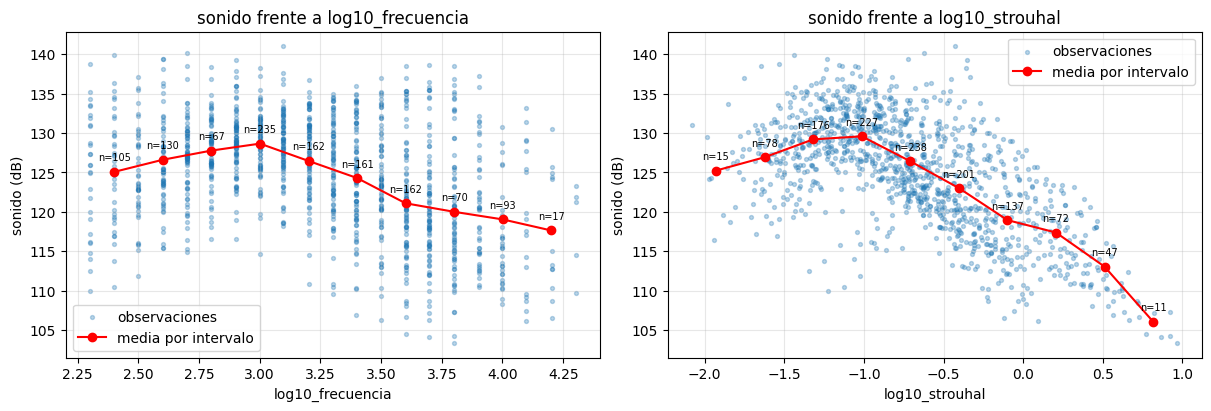

In [6]:
# H2: asociación de cada variable con el sonido.
# Pearson mide relación lineal; Spearman, relación monótona (que solo sube o solo baja).
predictores_eda = VARIABLES + ["log10_frecuencia", "log10_strouhal"]
asociacion = pd.DataFrame({
    "Pearson": eda[predictores_eda].corrwith(eda["sonido"]),
    "Spearman": eda[predictores_eda].corrwith(eda["sonido"], method="spearman"),
})
display(asociacion.round(3))
display(eda[VARIABLES].corr().round(2))          # correlación entre predictores

# Sonido frente a log10(frecuencia) y log10(Strouhal), con la media por intervalos.
fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for a, col in zip(ax, ["log10_frecuencia", "log10_strouhal"]):
    intervalos = pd.cut(eda[col], 10)            # 10 intervalos del mismo ancho
    medias = eda.groupby(intervalos, observed=True)["sonido"].agg(["mean", "size"])
    centros = [intervalo.mid for intervalo in medias.index]

    a.scatter(eda[col], eda["sonido"], s=8, alpha=0.3, label="observaciones")
    a.plot(centros, medias["mean"], "o-", color="red", label="media por intervalo")
    # Tamaño de cada intervalo escrito sobre su punto.
    for x, media, n in zip(centros, medias["mean"], medias["size"]):
        a.annotate(f"n={int(n)}", (x, media), textcoords="offset points", xytext=(0, 8),
                   fontsize=7, ha="center")
    a.set(xlabel=col, ylabel="sonido (dB)", title=f"sonido frente a {col}")
    a.legend()
plt.show()

**H2 se confirma.** La correlación con el sonido pasa de −0.40 (`frecuencia`) a −0.63 (`log10_strouhal`). Además, el sonido forma una U invertida en $\log_{10}St$: sube hasta $\log_{10}St\approx-1$ y después cae más de 20 dB, una curva que una recta no puede representar. Entre los predictores, `angulo` y `espesor` están correlacionadas (0.75), lo que motiva probar Ridge.

,n,media,mediana,desviacion,q1,q3
velocidad,,,,,,
31.7,220,123.94,124.19,6.65,119.90,128.94
39.6,373,123.45,124.49,7.24,118.21,129.29
55.5,222,125.67,126.52,6.31,121.78,130.18
71.3,387,125.99,127.05,7.13,121.31,131.28


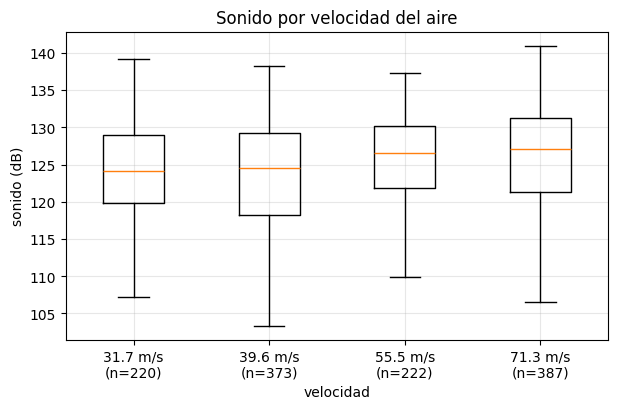

In [7]:
# H3: sonido por grupos de velocidad (el experimento usa 4 velocidades), con el tamaño de cada grupo.
por_velocidad = eda.groupby("velocidad")["sonido"].agg(
    n="size", media="mean", mediana="median", desviacion="std",
    q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75))
display(por_velocidad.round(2))

# Diagrama de caja por velocidad; la etiqueta incluye el tamaño del grupo.
grupos_sonido = [grupo["sonido"] for _, grupo in eda.groupby("velocidad")]
etiquetas = [f"{v} m/s\n(n={n})" for v, n in por_velocidad["n"].items()]
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(grupos_sonido, tick_labels=etiquetas)
ax.set(xlabel="velocidad", ylabel="sonido (dB)", title="Sonido por velocidad del aire")
plt.show()

**H3 se confirma solo en parte.** La mediana sube de 124.2 dB (31.7 m/s, $n=220$) a 127.1 dB (71.3 m/s, $n=387$). Pero el aumento es pequeño comparado con la dispersión dentro de cada grupo (desviación de 6 a 7 dB), y 31.7 y 39.6 m/s casi no se distinguen. La velocidad sola explica poco; su papel es más claro dentro del número de Strouhal, donde divide a la frecuencia por el espesor.

### Registro de hallazgos y decisiones

| Hallazgo | Evidencia | Decisión | Riesgo de fuga |
|---|---|---|---|
| Sin faltantes, duplicados ni valores fuera de dominio | Auditoría | Conservar las 1503 filas, sin limpieza | Ninguno: solo se revisan formato y reglas físicas |
| `frecuencia` y `espesor` muy asimétricas (2.17 y 1.66) | Histogramas (H1) | Usarlas en escala logarítmica dentro de la variable nueva | Ninguno: el logaritmo es una fórmula fija, no aprende nada de los datos |
| El sonido se ordena por $St=f\delta/U$, con forma de U invertida | Correlación −0.63 frente a −0.40; medias por intervalo (H2) | Representación alternativa con $\log_{10}St$ y $(\log_{10}St)^2$ | Bajo: fórmulas fijas, decididas solo con desarrollo y evaluadas con los mismos pliegues |
| `angulo` y `espesor` correlacionadas (0.75) | Matriz de correlación | Incluir Ridge y Lasso en la comparación | Ninguno |
| Efecto de la velocidad pequeño frente a la dispersión | Medianas y tamaños por grupo (H3) | Dejar `velocidad` como variable numérica | Ninguno |
| Valores altos de `espesor` válidos | Corresponden a ángulos altos | No eliminar valores extremos | Eliminarlos por estar fuera de los bigotes sesgaría la evaluación |
| Escalas muy distintas (Hz frente a metros) | `describe()` | Estandarizar dentro de cada pliegue | Alto si el escalador se ajustara con todo desarrollo antes de la validación cruzada; por eso se ajusta en cada pliegue |

## 6b. Validación cruzada

### Representaciones

1. **Original:** las cinco variables, estandarizadas.
2. **Alternativa:** las cinco variables más dos variables nuevas, todas estandarizadas:
   - $s_1=\log_{10}St=\log_{10}\!\left(\dfrac{\texttt{frecuencia}\cdot\texttt{espesor}}{\texttt{velocidad}}\right)$. Siempre está definida, porque las tres variables son positivas. No tiene unidades: Hz × m / (m/s) = 1.
   - $s_2=s_1^2$, que permite representar la curva en forma de U invertida. Tampoco tiene unidades.

   El modelo sigue siendo lineal en sus parámetros: solo cambian las columnas que recibe.

### Reglas fijadas antes de comparar resultados

- **Pliegues.** Los 5 pliegues de `KFold(shuffle=True, random_state=2026)`, iguales para todos los candidatos.
- **Preprocesamiento.** En cada pliegue, el escalador se ajusta solo con las filas de entrenamiento de ese pliegue. Las variables nuevas son fórmulas fijas, así que no aprenden nada.
- **Candidatos.**
  - Referencia constante: la media del entrenamiento del pliegue (para RMSE) y la mediana (para MAE).
  - OLS, Ridge y Lasso con las dos representaciones.
  - Grilla $\Lambda=\{0.001,\ 0.01,\ 0.1,\ 1,\ 10\}$ para Ridge ($\lambda_2$) y Lasso ($\lambda_1$), la misma del problema 5.
- **Criterio principal.** RMSE promedio de los 5 pliegues.
- **Selección.** El candidato regularizado es la combinación (representación, modelo, $\lambda$) con menor RMSE promedio. Su representación queda fijada, y OLS se evalúa con esa misma representación.
- **Desempate.** Si dos candidatos difieren en menos de 0.001 dB, se prefiere, en este orden: la representación original, el mayor $\lambda$, y Lasso antes que Ridge (porque usa menos variables).

In [8]:
LAMBDAS = [1e-3, 1e-2, 1e-1, 1.0, 10.0]
TOL_EMPATE = 1e-3     # dB


def representacion(df, nombre):
    """Matriz de predictores sin estandarizar para la representación indicada.

    "original" usa las cinco variables; "alternativa" agrega log10(St) y su cuadrado.
    """
    X = df[VARIABLES].copy()
    if nombre == "alternativa":
        X["log10_strouhal"] = np.log10(df["frecuencia"] * df["espesor"] / df["velocidad"])
        X["log10_strouhal_2"] = X["log10_strouhal"] ** 2
    return X


def crear_modelo(nombre, lam):
    """Modelo propio sin entrenar: "OLS", "Ridge" (con lam2 = lam) o "Lasso" (con lam1 = lam)."""
    if nombre == "OLS":
        return RegresionOLS()
    if nombre == "Ridge":
        return RegresionRidge(lam)
    return LassoProximal(lam)


def rmse(y, pred):
    """Raíz del error cuadrático medio, en las mismas unidades que y (dB)."""
    return float(np.sqrt(mean_squared_error(y, pred)))


y_des = desarrollo[OBJETIVO].to_numpy()
filas = []

# --- Referencia constante: no usa predictores ---
for k, (idx_ent, idx_val) in enumerate(pliegues, start=1):
    y_ent, y_val = y_des[idx_ent], y_des[idx_val]
    pred_media = np.full(len(y_val), y_ent.mean())          # mejor constante para el RMSE
    pred_mediana = np.full(len(y_val), np.median(y_ent))    # mejor constante para el MAE
    filas.append({"representacion": "ninguna", "modelo": "Referencia", "lambda": np.nan, "pliegue": k,
                  "RMSE": rmse(y_val, pred_media), "MAE": mean_absolute_error(y_val, pred_mediana)})

# --- Modelos: (representación, modelo, lambda) ---
candidatos = []
for rep in ("original", "alternativa"):
    candidatos.append((rep, "OLS", np.nan))
    candidatos += [(rep, "Ridge", lam) for lam in LAMBDAS]
    candidatos += [(rep, "Lasso", lam) for lam in LAMBDAS]

for rep, nombre, lam in candidatos:
    X_des = representacion(desarrollo, rep).to_numpy()
    for k, (idx_ent, idx_val) in enumerate(pliegues, start=1):
        y_ent, y_val = y_des[idx_ent], y_des[idx_val]
        # El escalador aprende media y desviación SOLO con el entrenamiento del pliegue.
        escalador = StandardScaler().fit(X_des[idx_ent])
        modelo = crear_modelo(nombre, lam).fit(escalador.transform(X_des[idx_ent]), y_ent)
        assert modelo.motivo_parada_ in ("solucion directa", "convergencia")
        pred = modelo.predict(escalador.transform(X_des[idx_val]))
        filas.append({"representacion": rep, "modelo": nombre, "lambda": lam, "pliegue": k,
                      "RMSE": rmse(y_val, pred), "MAE": mean_absolute_error(y_val, pred)})

# Tabla completa de validación (una fila por candidato y pliegue).
cv = pd.DataFrame(filas)
cv.to_csv(RESULTADOS / "p6_validacion_cv.csv", index=False)

# Resumen por candidato: promedio y desviación entre pliegues.
# dropna=False porque OLS y la referencia tienen lambda = NaN.
resumen_cv = (cv.groupby(["representacion", "modelo", "lambda"], dropna=False, sort=False)
              .agg(RMSE_medio=("RMSE", "mean"), RMSE_desv=("RMSE", "std"),
                   MAE_medio=("MAE", "mean"), MAE_desv=("MAE", "std"))
              .reset_index())
resumen_cv

,representacion,modelo,lambda,RMSE_medio,RMSE_desv,MAE_medio,MAE_desv
0,ninguna,Referencia,NaN,7.0142,0.3682,5.6951,0.3128
1,original,OLS,NaN,4.8440,0.4047,3.7759,0.3416
2,original,Ridge,0.001,4.8439,0.4046,3.7766,0.3417
3,original,Ridge,0.010,4.8436,0.4037,3.7829,0.3426
4,original,Ridge,0.100,4.8891,0.3977,3.8773,0.3549
5,original,Ridge,1.000,5.7111,0.3712,4.6708,0.3620
6,original,Ridge,10.000,6.7819,0.3666,5.5496,0.3288
7,original,Lasso,0.001,4.8440,0.4047,3.7761,0.3417
8,original,Lasso,0.010,4.8440,0.4045,3.7780,0.3423
9,original,Lasso,0.100,4.8521,0.4042,3.8021,0.3475


In [9]:
# RMSE (dB) de cada candidato en cada pliegue.
cv_para_tabla = cv.assign(lam=cv["lambda"].fillna("-"))          # "-" en lugar de NaN para mostrar
cv_para_tabla.pivot_table(index=["representacion", "modelo", "lam"], columns="pliegue",
                          values="RMSE", sort=False).round(3)

pliegue                              1      2      3      4      5
representacion modelo     lam                                     
ninguna        Referencia -      7.372  7.052  6.394  7.089  7.164
original       OLS        -      4.727  5.032  4.210  4.975  5.276
               Ridge      0.001  4.727  5.033  4.210  4.973  5.276
                          0.01   4.730  5.042  4.211  4.959  5.275
                          0.1    4.824  5.143  4.261  4.917  5.300
                          1.0    5.907  5.931  5.077  5.683  5.958
                          10.0   7.120  6.853  6.158  6.838  6.941
               Lasso      0.001  4.727  5.033  4.210  4.974  5.276
                          0.01   4.729  5.036  4.210  4.970  5.276
                          0.1    4.755  5.078  4.215  4.936  5.276
                          1.0    5.652  5.899  4.875  5.511  5.812
                          10.0   7.372  7.052  6.394  7.089  7.164
alternativa    OLS        -      3.905  4.315  3.790  4.445  4.660
               Ridge      0.001  3.904  4.317  3.787  4.445  4.660
                          0.01   3.910  4.338  3.773  4.455  4.667
                          0.1    4.154  4.590  3.887  4.688  4.852
                          1.0    5.308  5.452  4.680  5.504  5.587
                          10.0   6.794  6.592  5.887  6.580  6.695
               Lasso      0.001  3.904  4.315  3.789  4.446  4.660
                          0.01   3.902  4.317  3.786  4.453  4.660
                          0.1    3.921  4.362  3.782  4.570  4.693
                          1.0    5.095  5.291  4.594  5.559  5.479
                          10.0   7.372  7.052  6.394  7.089  7.164

In [10]:
# --- Selección con la regla fijada antes de ver los resultados ---
regularizados = resumen_cv.query("modelo in ['Ridge', 'Lasso']").copy()
mejor_rmse = regularizados["RMSE_medio"].min()

# Candidatos empatados: a menos de TOL_EMPATE del mejor.
empatados = regularizados[regularizados["RMSE_medio"] <= mejor_rmse + TOL_EMPATE].copy()

# Desempate: 1) representación original, 2) mayor lambda, 3) Lasso antes que Ridge.
# Las columnas "orden_*" valen 0 para la opción preferida, así que se ordenan de menor a mayor.
empatados["orden_rep"] = (empatados["representacion"] != "original").astype(int)
empatados["orden_modelo"] = (empatados["modelo"] != "Lasso").astype(int)
elegido = empatados.sort_values(["orden_rep", "lambda", "orden_modelo"],
                                ascending=[True, False, True]).iloc[0]

REP = elegido["representacion"]
ols_cv = resumen_cv.query("representacion == @REP and modelo == 'OLS'").iloc[0]

# Registro de la selección (lo pide el taller).
seleccion = {
    "regla": "menor RMSE medio en 5 pliegues; empate < 0.001 dB -> representacion original, "
             "mayor lambda, Lasso sobre Ridge",
    "grilla_lambda": LAMBDAS,
    "candidatos_empatados": empatados[["representacion", "modelo", "lambda", "RMSE_medio"]].to_dict("records"),
    "representacion": REP,
    "regularizado": {"modelo": elegido["modelo"], "lambda": float(elegido["lambda"]),
                     "RMSE_medio_cv": float(elegido["RMSE_medio"]), "RMSE_desv_cv": float(elegido["RMSE_desv"])},
    "OLS": {"RMSE_medio_cv": float(ols_cv["RMSE_medio"]), "RMSE_desv_cv": float(ols_cv["RMSE_desv"])},
    "referencia": {"RMSE_medio_cv": float(resumen_cv.iloc[0]["RMSE_medio"])},
}
with open(RESULTADOS / "p6_seleccion.json", "w", encoding="utf-8") as f:
    json.dump(seleccion, f, indent=2, ensure_ascii=False)

print("Candidatos dentro de la tolerancia de empate:")
display(empatados[["representacion", "modelo", "lambda", "RMSE_medio", "RMSE_desv"]])
print(f"Representación: {REP} | Regularizado: {elegido['modelo']} con lambda = {elegido['lambda']}")

Candidatos dentro de la tolerancia de empate:


,representacion,modelo,lambda,RMSE_medio,RMSE_desv
13,alternativa,Ridge,0.001,4.2229,0.3677
18,alternativa,Lasso,0.001,4.2229,0.3670
19,alternativa,Lasso,0.010,4.2235,0.3700


Representación: alternativa | Regularizado: Lasso con lambda = 0.01


**Interpretación.**

- La referencia constante tiene RMSE de 7.01 dB. OLS baja a 4.84 dB con la representación original y a **4.22 dB** con la alternativa; la alternativa gana en los 5 pliegues.
- La regularización no ayuda: con $\lambda\le0.01$ Ridge y Lasso quedan prácticamente iguales a OLS, y con $\lambda$ mayores empeoran. Con unas 960 filas para 5 a 7 coeficientes, OLS ya es estable.
- Tres candidatos empatan (diferencia menor que 0.001 dB) y la regla de desempate elige **Lasso con $\lambda_1=0.01$** en la representación alternativa.

## 6c. Evaluación final en prueba

La representación y los hiperparámetros quedan congelados. Los finalistas son la referencia constante, OLS y el modelo regularizado elegido. Se entrenan una vez con todo el conjunto de desarrollo (con el escalador ajustado en desarrollo) y se evalúan **una sola vez** en prueba.

**Segmentos.** Para ver dónde se equivoca más el modelo, se separa prueba en frecuencias bajas y altas. El umbral es la mediana de `frecuencia` en desarrollo, así que se define sin mirar prueba.

In [11]:
# Matrices con la representación elegida.
X_des = representacion(desarrollo, REP).to_numpy()
X_pru = representacion(prueba, REP).to_numpy()
y_pru = prueba[OBJETIVO].to_numpy()

# El escalador aprende solo con desarrollo y se aplica igual a prueba.
escalador = StandardScaler().fit(X_des)
X_des_esc = escalador.transform(X_des)
X_pru_esc = escalador.transform(X_pru)

# Finalistas entrenados con todo desarrollo.
nombre_regularizado = f"{elegido['modelo']} (lambda={elegido['lambda']:g})"
finalistas = {
    "OLS": RegresionOLS().fit(X_des_esc, y_des),
    nombre_regularizado: crear_modelo(elegido["modelo"], float(elegido["lambda"])).fit(X_des_esc, y_des),
}
for nombre, modelo in finalistas.items():
    modelo.guardar_parametros(PARAMETROS / f"p6_{nombre.split()[0]}.json")

# --- Única evaluación en prueba ---
predicciones = {"Referencia (media)": np.full(len(y_pru), y_des.mean())}
for nombre, modelo in finalistas.items():
    predicciones[nombre] = modelo.predict(X_pru_esc)

filas = []
for nombre, pred in predicciones.items():
    # La referencia usa la mediana para el MAE (la mejor constante para esa métrica).
    if nombre.startswith("Referencia"):
        pred_mae = np.full(len(y_pru), np.median(y_des))
    else:
        pred_mae = pred
    filas.append({"modelo": nombre, "MAE": mean_absolute_error(y_pru, pred_mae),
                  "RMSE": rmse(y_pru, pred), "R2": r2_score(y_pru, pred)})
evaluacion = pd.DataFrame(filas).set_index("modelo")
evaluacion.to_csv(RESULTADOS / "p6_evaluacion_final.csv")

# Predicciones finales con id y valor observado (las pide el taller).
salida = prueba[["id", OBJETIVO]].rename(columns={OBJETIVO: "sonido_observado"})
for nombre, pred in predicciones.items():
    salida[f"pred_{nombre.split()[0]}"] = pred
salida.to_csv(RESULTADOS / "p6_predicciones_prueba.csv", index=False)

print("La referencia usa la media de desarrollo para RMSE y R2, y la mediana para MAE.")
evaluacion

La referencia usa la media de desarrollo para RMSE y R2, y la mediana para MAE.


,MAE,RMSE,R2
modelo,,,
Referencia (media),5.2047,6.3957,-0.0029
OLS,3.2463,4.1147,0.5849
Lasso (lambda=0.01),3.2448,4.1135,0.5851


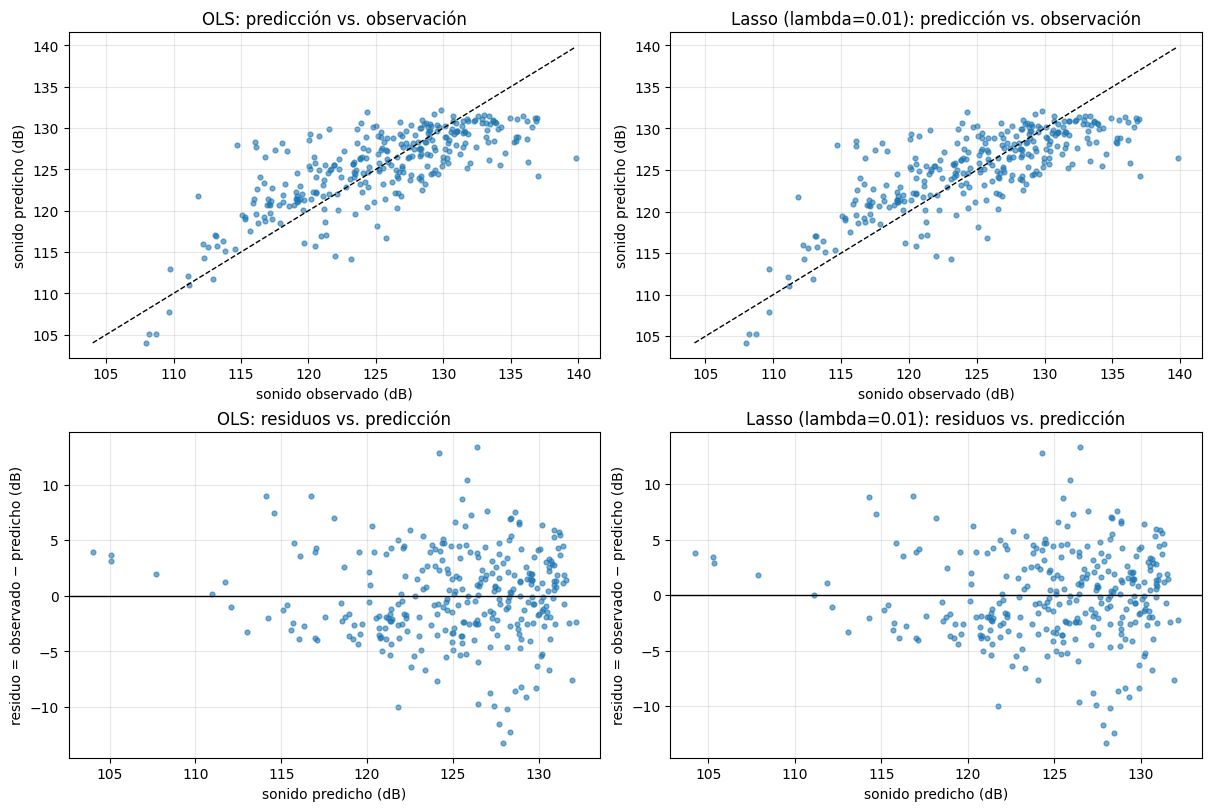

In [12]:
# Arriba: predicción frente a observación. Abajo: residuo frente a predicción.
fig, ax = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for j, nombre in enumerate(finalistas):
    pred = predicciones[nombre]
    residuo = y_pru - pred

    ax[0, j].scatter(y_pru, pred, s=12, alpha=0.6)
    limites = [min(y_pru.min(), pred.min()), max(y_pru.max(), pred.max())]
    ax[0, j].plot(limites, limites, "k--", lw=1)            # diagonal = predicción perfecta
    ax[0, j].set(xlabel="sonido observado (dB)", ylabel="sonido predicho (dB)",
                 title=f"{nombre}: predicción vs. observación")

    ax[1, j].scatter(pred, residuo, s=12, alpha=0.6)
    ax[1, j].axhline(0, color="black", lw=1)
    ax[1, j].set(xlabel="sonido predicho (dB)", ylabel="residuo = observado − predicho (dB)",
                 title=f"{nombre}: residuos vs. predicción")
plt.show()

In [13]:
# Errores por segmento de frecuencia. El umbral se calcula con desarrollo, no con prueba.
umbral_frec = desarrollo["frecuencia"].median()
segmento = np.where(prueba["frecuencia"] <= umbral_frec,
                    f"baja (<= {umbral_frec:g} Hz)", f"alta (> {umbral_frec:g} Hz)")

filas = []
for nombre in finalistas:
    for seg in np.unique(segmento):
        en_segmento = segmento == seg
        residuo = y_pru[en_segmento] - predicciones[nombre][en_segmento]
        filas.append({"modelo": nombre, "segmento": seg, "n": int(en_segmento.sum()),
                      "MAE": np.mean(np.abs(residuo)),
                      "RMSE": np.sqrt(np.mean(residuo ** 2)),
                      "residuo medio": residuo.mean()})        # > 0: el modelo subestima
por_segmento = pd.DataFrame(filas)
por_segmento.round(3)

,modelo,segmento,n,MAE,RMSE,residuo medio
0,OLS,alta (> 1600 Hz),155,3.019,3.686,-0.311
1,OLS,baja (<= 1600 Hz),146,3.488,4.526,0.184
2,Lasso (lambda=0.01),alta (> 1600 Hz),155,3.006,3.670,-0.300
3,Lasso (lambda=0.01),baja (<= 1600 Hz),146,3.499,4.538,0.175


**Interpretación.**

- En prueba, OLS y Lasso son prácticamente iguales (RMSE 4.11 dB, MAE 3.25 dB, $R^2=0.585$) y reducen el RMSE de la referencia (6.40 dB) en un 36 %. El resultado es parecido al de la validación cruzada.
- **Errores sistemáticos:** el modelo subestima los sonidos altos y sobreestima los bajos; los errores más grandes (hasta −13 dB) aparecen en predicciones de 125 a 130 dB. Hay relaciones no lineales que el modelo no captura.
- **Segmentos:** el error es mayor en frecuencias bajas (RMSE 4.53 dB) que en altas (3.69 dB).
- **Limitación:** con $R^2\approx0.59$ queda cerca del 40 % de la variabilidad sin explicar. No se reajustó ningún modelo.

## 6d. Alcance de la evaluación y elección del modelo

**¿Qué tipo de generalización mide una partición aleatoria?** Casi cada ensayo de prueba tiene en desarrollo otro con la misma cuerda, velocidad y ángulo, a otra frecuencia. Por eso se mide qué tan bien se completan configuraciones ya ensayadas, no configuraciones nuevas.

**¿Cómo evaluar condiciones experimentales nuevas?** Partiendo por configuración y no por fila, por ejemplo con `GroupKFold` agrupando por (cuerda, velocidad, ángulo), para que todo el espectro de una configuración quede en prueba. Esperaríamos errores mayores; la evaluación hecha no demuestra esa capacidad.

**¿Qué evidencia respalda la elección entre OLS, Ridge y Lasso?** Ninguna a favor de uno: con $\lambda\le0.01$ difieren en menos de 0.01 dB. Lasso se eligió por la regla de desempate, no por ser mejor. Lo que sí mejora el error es la representación con Strouhal (unos 0.6 dB en los 5 pliegues).

Los coeficientes describen asociaciones en estos ensayos, no causas: las variables están correlacionadas y el experimento no las varía de forma independiente.